# Plot Spectra Results

This notebook loads pre-computed spectral analysis results for a list of ROMY events
from JSON files `events/event_<DATE>/spectral_analysis_<DATE>.json` (produced by `04_XROMY_event_analysis_spec.py`)
and generates overview plots.

You can choose:
- which **events** to include
- whether to use **rotation** or **translation** data
- whether to plot **FFT** or **PSD**
- whether to plot **normal** or **smoothed** spectra (if available)

Run the cells from top to bottom, adjusting the configuration cell as needed.

## Notebook Overview
This notebook plots spectral products (PSD/ASD) from per-event spectral analyses and compares them to noise/model references.

**Main workflow**
- Load per-event spectral JSON files.
- Extract channel-wise PSD/ASD quantities.
- Compute/plot event stacks or medians.
- Compare against low-noise/reference models.
- Save spectral comparison figures.

In [1]:
import os
import json
import yaml
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from typing import Dict, Any, List
from pandas import read_csv
from matplotlib.colors import Normalize
from scipy.signal import savgol_filter

%matplotlib inline

## Configuration

Edit this cell to select which events and spectra to plot.

In [2]:
# List of event dates to include (strings like '20230908')
events: list[str] = [
  '20190514',
  '20230908',
  '20230912',
  # '20231202',
  # '20240314',
  # '20240322',
  '20240323',
  # '20240414',
  # '20240422',
  # '20240815',
  # '20240915',
  # '20241023',
  # '20250513',
  '20250602',
  '20251206',
  # '20251212',
  # '20251227',
  # '20260107',
]

# eventlist = yaml.load(open("events_list.yml"), Loader=yaml.FullLoader)
# events = eventlist['events']

# Base directory where event folders live
base_dir: str = "./events"

# Stream type: 'rotation', 'translation', 'rotation_RT', or 'translation_RT'
stream_type: str = "rotation_RT"

# Spectrum type: 'fft' (amplitude) or 'psd'
spectrum_type: str = "psd"  # or "fft"

# Whether to prefer smoothed spectra if available
# - For Savitzky-Golay smoothing: uses 'fft_smooth' / 'psd_smooth'
# - For octave-band medians: uses 'fft_octave_median' / 'psd_octave_median'
use_smooth: bool = False

# List of channel substrings to include (e.g. ['JZ', 'JT']); empty list means all channels
channel_substrings: list[str] = ["JZ", "JT"]

# Plot style
log_frequency: bool = True
log_value: bool = True

# Alpha for individual curves
curve_alpha: float = 0.5


## Helper functions to load and extract spectra

In [3]:
def load_event_json(event: str) -> Dict[str, Any] | None:
    """Load spectral JSON for a single event.

    Expects files at `events/event_<DATE>/spectral_analysis_<DATE>.json`.
    Returns the loaded dict or None if the file does not exist.
    """
    event_dir = os.path.join(base_dir, f"event_{event}")
    json_path = os.path.join(event_dir, f"spectral_analysis_{event}.json")

    if not os.path.exists(json_path):
        print(f"[WARN] JSON file not found for event {event}: {json_path}")
        return None

    with open(json_path, "r") as f:
        data = json.load(f)
    return data

In [4]:
def _choose_spectrum_dict(channel_data: Dict[str, Any]) -> Dict[str, Any] | None:
    """Return the appropriate spectrum sub-dictionary for this channel.

    Depending on SPECTRUM_TYPE ('fft' or 'psd') and USE_SMOOTH, this function
    selects among keys:
      - 'fft', 'fft_smooth', 'fft_octave_median'
      - 'psd', 'psd_smooth', 'psd_octave_median'
    """
    if spectrum_type == "fft":
        # Priority order if smoothing requested
        if use_smooth:
            if "fft_smooth" in channel_data:
                return channel_data["fft_smooth"]
            if "fft_octave_median" in channel_data:
                return channel_data["fft_octave_median"]
        # Fallback to normal FFT
        return channel_data.get("fft")

    if spectrum_type == "psd":
        if use_smooth:
            if "psd_smooth" in channel_data:
                return channel_data["psd_smooth"]
            if "psd_octave_median" in channel_data:
                return channel_data["psd_octave_median"]
        return channel_data.get("psd")

    return None

In [5]:
def _extract_freq_and_value(spec_dict: Dict[str, Any]) -> tuple[np.ndarray, np.ndarray] | tuple[None, None]:
    """Extract frequency and value arrays from a spectrum dict.

    Handles both normal and octave-median representations, where fields are:
      - Normal FFT: {'frequency': [...], 'amplitude': [...]}\n",
      - Normal PSD: {'frequency': [...], 'psd': [...]}\n",
      - Octave medians: {'frequency_center': [...], 'value_median': [...]}.
    """
    if spec_dict is None:
        return None, None

    # Octave-band representation
    if "frequency_center" in spec_dict and "value_median" in spec_dict:
        f = np.asarray(spec_dict["frequency_center"], dtype=float)
        v = np.asarray(spec_dict["value_median"], dtype=float)
        return f, v

    # Normal FFT / PSD representation
    f = np.asarray(spec_dict.get("frequency", []), dtype=float)
    if spectrum_type == "fft":
        v = np.asarray(spec_dict.get("amplitude", []), dtype=float)
    else:
        v = np.asarray(spec_dict.get("psd", []), dtype=float)

    if f.size == 0 or v.size == 0:
        return None, None
    return f, v

In [6]:
def collect_event_curves(event: str) -> list[dict[str, Any]]:
    """Collect spectral curves (frequency, value, label) for one event."""

    data = load_event_json(event)
    if data is None:
        return []

    event_info = data.get("event_info", {})
    event_mag = event_info.get("magnitude", None)

    spectra_root = data.get("spectra", {})
    stream_dict = spectra_root.get(stream_type, {})

    curves: list[dict[str, Any]] = []

    for chan_id, chan_data in stream_dict.items():
        if channel_substrings and not any(sub in chan_id for sub in channel_substrings):
            continue

        spec = _choose_spectrum_dict(chan_data)
        if spec is None:
            continue

        f, v = _extract_freq_and_value(spec)
        if f is None or v is None:
            continue

        curves.append(
            {
                "frequency": f,
                "value": v,
                "label": f"{event} | {chan_id}",
                "magnitude": event_mag,
            }
        )

    if not curves:
        print(f"[INFO] No curves collected for event {event} (check config and smoothing choice).")

    return curves

In [7]:
def apply_savgol_filter(
        frequency: np.ndarray,
        values: np.ndarray,
        window_length: int = 21,
        polyorder: int = 3,
    ) -> tuple[np.ndarray, np.ndarray]:
    """Smooth a spectrum with Savitzky-Golay filtering.

    Parameters
    ----------
    frequency : np.ndarray
        Frequency axis (used only for length/validity checks).
    values : np.ndarray
        Spectrum values to smooth.
    window_length : int
        Odd window length for Savitzky-Golay filter.
    polyorder : int
        Polynomial order for Savitzky-Golay filter.
    """
    from scipy.signal import savgol_filter
    
    f = np.asarray(frequency, dtype=float)
    v = np.asarray(values, dtype=float)

    if f.size != v.size or v.size < 5:
        return v.copy()

    # Keep finite samples only for stable filtering.
    m = np.isfinite(v)
    if np.sum(m) < 5:
        return v.copy()

    v_out = v.copy()
    v_work = v[m]

    # Ensure valid odd window and polyorder < window_length.
    wl = int(window_length)
    if wl % 2 == 0:
        wl += 1
    wl = min(wl, v_work.size if v_work.size % 2 == 1 else v_work.size - 1)
    if wl < 3:
        return v.copy()

    po = min(int(polyorder), wl - 1)
    if po < 1:
        po = 1

    v_out[m] = savgol_filter(v_work, window_length=wl, polyorder=po, mode="interp")
    return np.array(f), np.array(v_out)

In [8]:
def apply_octave_filter(
    frequency: np.ndarray,
    values: np.ndarray,
    *,
    fraction: int = 12,                 # 1/12 octave bands
    statistic: str = "median",          # "median" or "mean"
    fmin: float | None = None,
    fmax: float | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """Aggregate a spectrum into fractional-octave bands.

    Returns
    -------
    fc : np.ndarray
        Geometric center frequency of each band that contains data.
    v_band : np.ndarray
        `median` or `mean` of samples within each band (same length as `fc`).

    Band definition (simple geometric 1/N-octave):
      half-width factor g = 2^( (1/N) / 2 )
      band for center f0 is [f0/g, f0*g]
    """
    f = np.asarray(frequency, dtype=float)
    v = np.asarray(values, dtype=float)

    if f.size != v.size or f.size < 3:
        return np.array([]), np.array([])

    m = np.isfinite(f) & np.isfinite(v) & (f > 0)
    if np.sum(m) < 3:
        return np.array([]), np.array([])

    f = f[m]
    v = v[m]

    if fmin is None:
        fmin = float(np.min(f))
    if fmax is None:
        fmax = float(np.max(f))

    bw = 1.0 / float(fraction)
    g = 2.0 ** (bw / 2.0)  # geometric half-width factor

    # Build band centers from fmin upward
    centers: list[float] = []
    fc = float(fmin)
    while fc <= fmax * g:
        centers.append(fc)
        fc *= 2.0 ** bw
    centers = np.asarray(centers, dtype=float)
    if centers.size == 0:
        return np.array([]), np.array([])

    f_lo = centers / g
    f_hi = centers * g

    fc_out: list[float] = []
    v_out: list[float] = []

    for i, (f0, lo, hi) in enumerate(zip(centers, f_lo, f_hi)):
        mb = (f >= lo) & (f < hi)
        if i == len(centers) - 1:
            mb = (f >= lo) & (f <= hi)  # include right edge on last band

        if not np.any(mb):
            continue

        vv = v[mb]
        if statistic.lower() == "mean":
            agg = float(np.mean(vv))
        elif statistic.lower() == "median":
            agg = float(np.median(vv))
        else:
            raise ValueError("statistic must be 'mean' or 'median'")

        fc_out.append(float(f0))
        v_out.append(agg)

    return np.asarray(fc_out, dtype=float), np.asarray(v_out, dtype=float)

### Load Noise Models

In [9]:
noise_models = read_csv(os.path.join("./data/", "low_noise_models.csv"))

## Plot overview spectra

This cell gathers the selected spectra for all configured events and plots them together.

In [10]:
apply_savgol = False
apply_octave = True

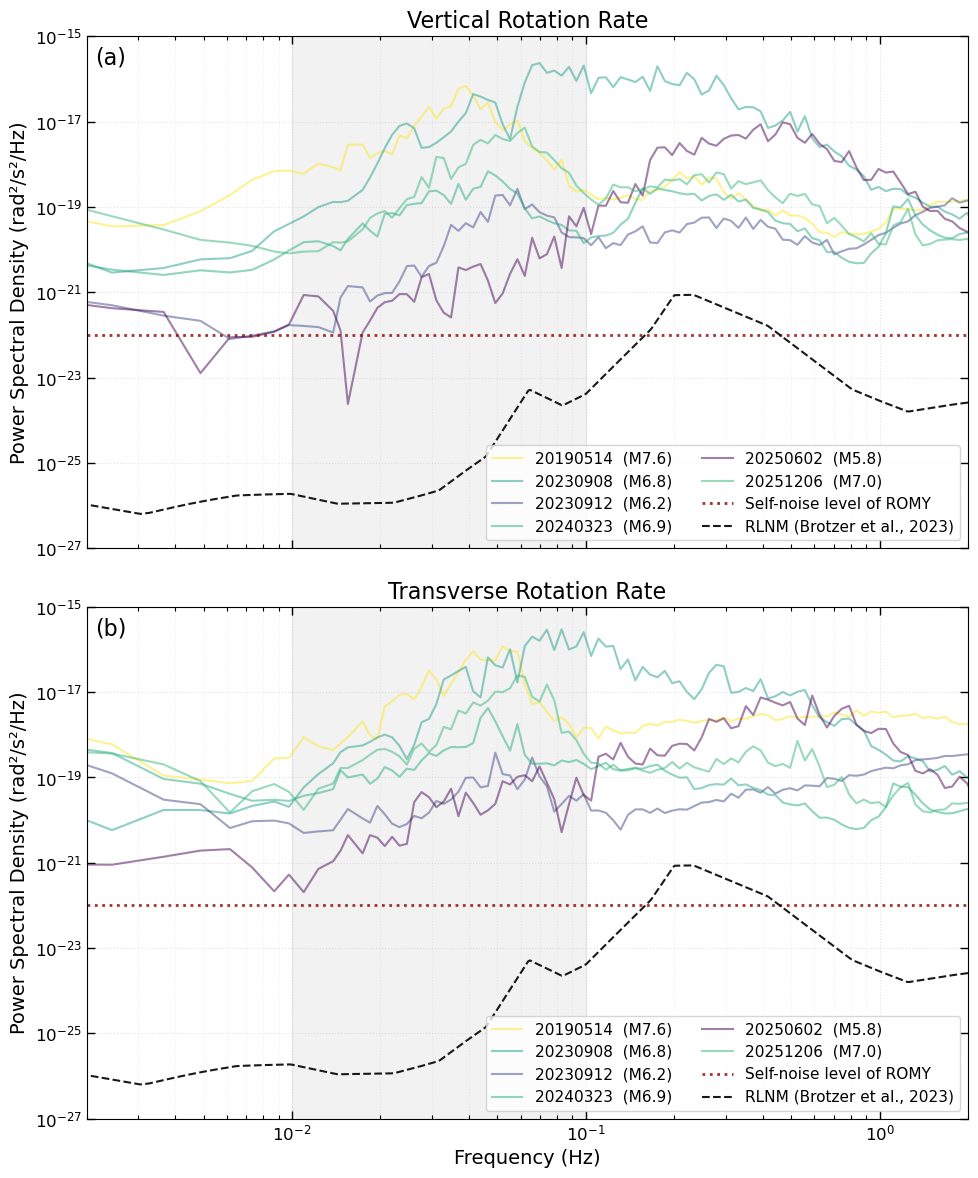

In [11]:
os.makedirs("./output/figures/spectra", exist_ok=True)

all_curves: list[dict[str, Any]] = []
for ev in events:
    ev_curves = collect_event_curves(ev)
    all_curves.extend(ev_curves)

# --- styling ---
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "legend.fontsize": 10,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

jz_curves = [c for c in all_curves if "JZ" in c["label"] and "JT" not in c["label"]]
jt_curves = [c for c in all_curves if "JT" in c["label"]]

mags = [c.get("magnitude") for c in all_curves if c.get("magnitude") is not None]
if mags:
    norm = Normalize(vmin=min(mags), vmax=max(mags))
    cmap = cm.viridis
else:
    norm = None
    cmap = None

xlab = "Frequency (Hz)"
ylab = "Amplitude" if spectrum_type == "fft" else "Power Spectral Density (rad²/s²/Hz)"
method_str = "smoothed" if use_smooth else "normal"

fig, (ax_jz, ax_jt) = plt.subplots(2, 1, figsize=(10, 12), sharex=True)

def prettify_ax(ax):
    ax.minorticks_on()
    ax.tick_params(which="both", direction="in", top=True, right=True)
    ax.tick_params(which="minor", length=3, width=0.8)
    ax.tick_params(which="major", length=6, width=1.0)
    ax.grid(True, which="major", ls=":", alpha=0.35)
    ax.grid(True, which="minor", ls=":", alpha=0.18)

def add_panel_tag(ax, tag: str):
    ax.text(
        0.01, 0.98, tag,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=16,
        # fontweight="bold",
        # bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6", alpha=0.85),
    )

for ax, curves, title, tag in [
    (ax_jz, jz_curves, "JZ", "(a)"),
    (ax_jt, jt_curves, "JT", "(b)"),
    ]:

    add_panel_tag(ax, tag)

    for c in curves:
        f = np.asarray(c["frequency"], dtype=float)
        v = np.asarray(c["value"], dtype=float)

        # smoothing
        if apply_savgol:
            f, v = apply_savgol_filter(f, v, window_length=31, polyorder=3)
        if apply_octave:
            f, v = apply_octave_filter(f, v, fraction=12, statistic="mean")

        # mask
        mask = np.isfinite(f) & np.isfinite(v) & (f > 0)
        mask = np.isfinite(f) & np.isfinite(v) & (f > 0)
        if spectrum_type == "psd" or log_value:
            mask &= v > 0
        f, v = f[mask], v[mask]
        if f.size == 0 or v.size == 0:
            continue

        mag = c.get("magnitude")
        color = cmap(norm(mag)) if (mag is not None and norm is not None) else None

        # extract date from label
        date = c['label'].split('|')[0].split('_')[-1]
        label = f"{date} (M{mag})"
        if log_frequency and log_value:
            ax.loglog(f, v, alpha=curve_alpha, color=color, label=label)
        elif log_frequency:
            ax.semilogx(f, v, alpha=curve_alpha, color=color, label=c["label"])
        elif log_value:
            ax.semilogy(f, v, alpha=curve_alpha, color=color, label=c["label"])
        else:
            ax.plot(f, v, alpha=curve_alpha, color=color, label=c["label"])

    ax.axhline(1e-22, color="darkred", alpha=0.8, ls=":", lw=2, label="Self-noise level of ROMY")

    f_nm = noise_models["frequency"]
    v_nm = noise_models["rlnm_rot_rate"]
    ax.loglog(f_nm, v_nm, alpha=0.9, color="black", ls="--", label="RLNM (Brotzer et al., 2023)")

    ax.set_ylabel(ylab)
    if "JT" in title:
        ax.set_title(f"Transverse Rotation Rate")
    elif "JZ" in title:
        ax.set_title(f"Vertical Rotation Rate")
    else:
        ax.set_title(f"{title}")

    ax.set_xlim(2e-3, 2)
    ax.set_ylim(1e-27, 1e-15)

    ax.fill_betweenx([1e-28, 1e-5], 0.01, 0.1, color="grey", alpha=0.1)

    prettify_ax(ax)

    if len(curves) <= 15:
        ax.legend(loc="lower right", ncol=2, fontsize=11)
    else:
        ax.legend(
            bbox_to_anchor=(1.2, 1),
            loc="lower right",
            ncol=2,
            borderaxespad=0.0,
            fontsize=11,
        )

ax_jt.set_xlabel(xlab)

plt.tight_layout()
plt.show()

fig.savefig(f"./output/figures/spectra/psd_events.png", dpi=150, bbox_inches="tight")

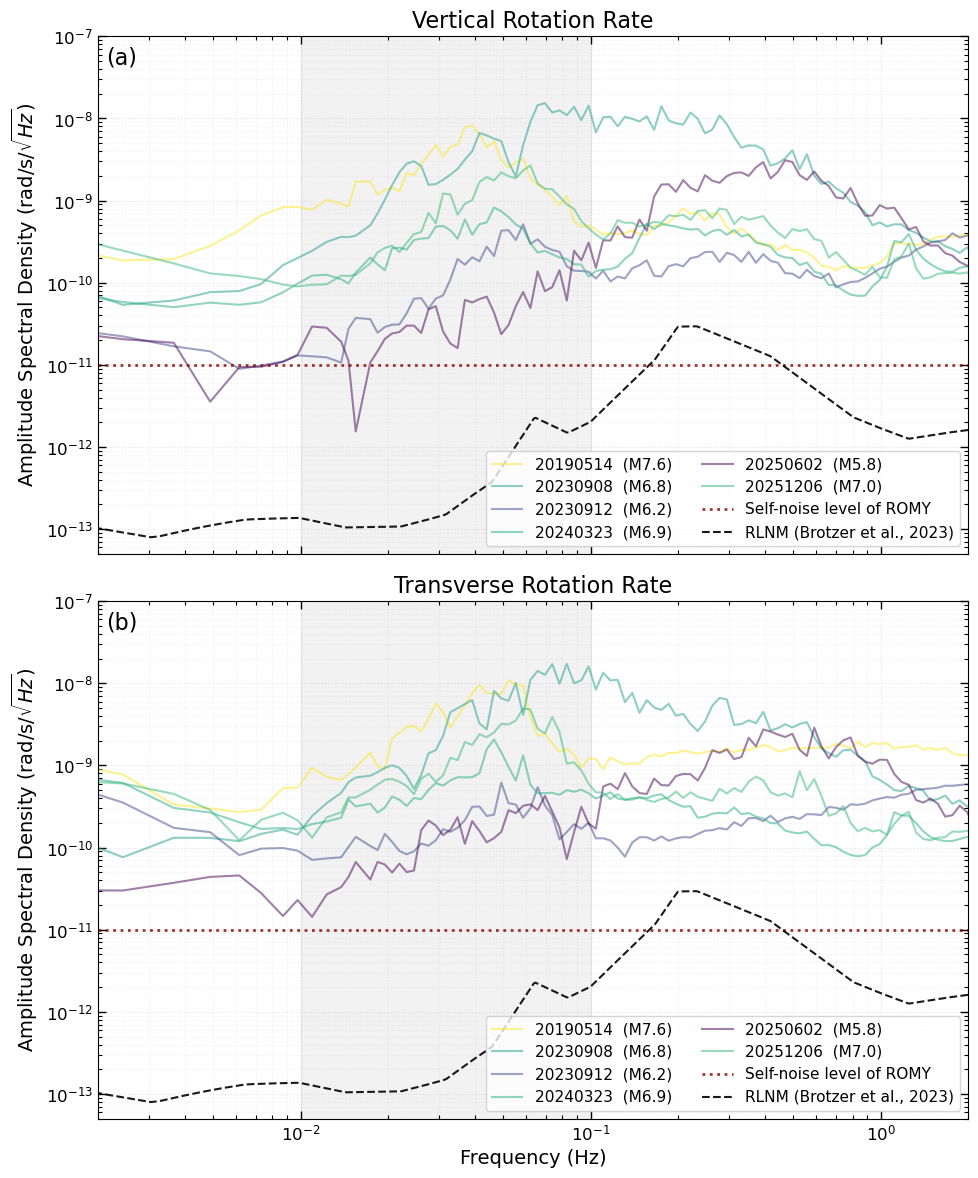

In [12]:
os.makedirs("./output/figures/publication", exist_ok=True)

all_curves: list[dict[str, Any]] = []
for ev in events:
    ev_curves = collect_event_curves(ev)
    all_curves.extend(ev_curves)

# --- styling ---
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "legend.fontsize": 10,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

jz_curves = [c for c in all_curves if "JZ" in c["label"] and "JT" not in c["label"]]
jt_curves = [c for c in all_curves if "JT" in c["label"]]

mags = [c.get("magnitude") for c in all_curves if c.get("magnitude") is not None]
if mags:
    norm = Normalize(vmin=min(mags), vmax=max(mags))
    cmap = cm.viridis
else:
    norm = None
    cmap = None

xlab = "Frequency (Hz)"
ylab = "Amplitude Spectral Density (rad/s/$\sqrt{Hz})$"
method_str = "smoothed" if use_smooth else "normal"

fig, (ax_jz, ax_jt) = plt.subplots(2, 1, figsize=(10, 12), sharex=True)

def prettify_ax(ax):
    ax.minorticks_on()
    ax.tick_params(which="both", direction="in", top=True, right=True)
    ax.tick_params(which="minor", length=3, width=0.8)
    ax.tick_params(which="major", length=6, width=1.0)
    ax.grid(True, which="major", ls=":", alpha=0.35)
    ax.grid(True, which="minor", ls=":", alpha=0.18)

def add_panel_tag(ax, tag: str):
    ax.text(
        0.01, 0.98, tag,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=16,
        # fontweight="bold",
        # bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6", alpha=0.85),
    )

for ax, curves, title, tag in [
    (ax_jz, jz_curves, "JZ", "(a)"),
    (ax_jt, jt_curves, "JT", "(b)"),
    ]:

    add_panel_tag(ax, tag)

    for c in curves:
        f = np.asarray(c["frequency"], dtype=float)
        v = np.asarray(c["value"], dtype=float)

        # smoothing
        if apply_savgol:
            f, v = apply_savgol_filter(f, v, window_length=31, polyorder=3)
        if apply_octave:
            f, v = apply_octave_filter(f, v, fraction=12, statistic="mean")

        # mask
        mask = np.isfinite(f) & np.isfinite(v) & (f > 0)
        mask = np.isfinite(f) & np.isfinite(v) & (f > 0)
        if spectrum_type == "psd" or log_value:
            mask &= v > 0
        f, v = f[mask], v[mask]
        if f.size == 0 or v.size == 0:
            continue

        # from psd to asd
        v = np.sqrt(v)

        mag = c.get("magnitude")
        color = cmap(norm(mag)) if (mag is not None and norm is not None) else None

        # extract date from label
        date = c['label'].split('|')[0].split('_')[-1]
        label = f"{date} (M{mag})"
        if log_frequency and log_value:
            ax.loglog(f, v, alpha=curve_alpha, color=color, label=label)
        elif log_frequency:
            ax.semilogx(f, v, alpha=curve_alpha, color=color, label=c["label"])
        elif log_value:
            ax.semilogy(f, v, alpha=curve_alpha, color=color, label=c["label"])
        else:
            ax.plot(f, v, alpha=curve_alpha, color=color, label=c["label"])

    ax.axhline(1e-11, color="darkred", alpha=0.8, ls=":", lw=2, label="Self-noise level of ROMY")

    f_nm = noise_models["frequency"]
    v_nm = np.sqrt(noise_models["rlnm_rot_rate"])
    ax.loglog(f_nm, v_nm, alpha=0.9, color="black", ls="--", label="RLNM (Brotzer et al., 2023)")

    ax.set_ylabel(ylab)
    if "JT" in title:
        ax.set_title(f"Transverse Rotation Rate")
    elif "JZ" in title:
        ax.set_title(f"Vertical Rotation Rate")
    else:
        ax.set_title(f"{title}")

    ax.set_xlim(2e-3, 2)
    ax.set_ylim(5e-14, 1e-7)

    ax.fill_betweenx([1e-28, 1e-5], 0.01, 0.1, color="grey", alpha=0.1)

    prettify_ax(ax)

    if len(curves) <= 15:
        ax.legend(loc="lower right", ncol=2, fontsize=11)
    else:
        ax.legend(
            bbox_to_anchor=(1.2, 1),
            loc="lower right",
            ncol=2,
            borderaxespad=0.0,
            fontsize=11,
        )

ax_jt.set_xlabel(xlab)

plt.tight_layout()
plt.show()

fig.savefig(f"./output/figures/publication/asd_events.png", dpi=150, bbox_inches="tight")